# Second-Look Lending — EDA, models and inclusive decision policy

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Break-Through-Tech/American-Express-1C-second-look-lending/blob/feature/second_lookup_lending/notebooks/second_look_lending.ipynb)

This notebook is the reproducible version of the project. It uses the same code as the web app (`backend/app/`), so the
numbers match what the app shows.

1. **EDA** — structure, target, missing values, segments, drift, numeric and categorical features, signal, leakage checks
2. **Features and split** — one row per loan, split by week
3. **Models** — Logistic Regression (baseline), Random Forest, LightGBM (+ Optuna)
4. **Decision policy** — cost model, inclusion gap, second-look policy, before / after
5. **Conclusions**

**How to run**
- **Colab:** put the dataset folder (with `csv_files/` and `solution.csv`) in Google Drive at `MyDrive/synth_home_credit`,
  then *Runtime → Run all*. The whole notebook takes about 10 minutes on the free tier.
- **Locally:** run from the `notebooks/` folder with the backend's virtual environment.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Break-Through-Tech/American-Express-1C-second-look-lending.git"
BRANCH = "feature/second_lookup_lending"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path("/content/repo").exists():
        !git clone -q -b {BRANCH} {REPO_URL} /content/repo
    !pip install -q -r /content/repo/backend/requirements.txt
    REPO = Path("/content/repo")
    DATA_DIR = Path("/content/drive/MyDrive/synth_home_credit")
else:
    REPO = Path.cwd().parent
    DATA_DIR = Path(os.environ.get("SLL_DATA_DIR", REPO / "data" / "synth_home_credit"))

assert (DATA_DIR / "csv_files").exists(), "Dataset not found: put it in data/synth_home_credit or set SLL_DATA_DIR"

# The backend reads these on import; notebook runs get their own artifacts folder
os.environ["SLL_DATA_DIR"] = str(DATA_DIR)
os.environ["SLL_ARTIFACTS_DIR"] = str(REPO / "backend" / "artifacts_notebook")
sys.path.insert(0, str(REPO / "backend"))
print("Dataset folder:", DATA_DIR.name)

Dataset folder: synth_home_credit


In [2]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from app import analysis, config, features, storage, training
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)

# Same colors as the web app
ESTABLISHED, THIN, SECOND_LOOK, BASELINE = "#2a78d6", "#eb6834", "#1baf7a", "#8a918e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

## 1. EDA

### 1.1 Structure and target

Everything joins on `case_id`. **Depth 0** tables have one row per loan and join directly. **Depth 1–2** tables have many
rows per loan and must be aggregated first. Files ending in `_0` / `_1` are parts of one table.

In [3]:
tables = pd.read_csv(DATA_DIR / "table_details.csv")
tables[["table", "depth", "grain_rows_per_case", "n_rows_train", "n_rows_test", "description"]]

,table,depth,grain_rows_per_case,n_rows_train,n_rows_test,description
0,base,0,1,1000000,200000,"Loan spine: one row per application, with the ..."
1,static_0,0,1,1000000,200000,Applicant static attributes known at decision ...
2,static_cb_0,0,0 or 1,700179,139971,Credit-bureau static summary; present only for...
3,person_1,1,1..2,1500222,300192,Person/demographic records (depth 1).
4,credit_bureau_a_1,1,0..8,3155263,628736,Credit-bureau contracts. EMPTY for thin-file a...
5,credit_bureau_a_2,2,0..n,4729114,945046,Sub-records (e.g. monthly payments) of each cr...
6,applprev_1,1,0..4,1997547,401046,Applicant's previous applications (depth 1).
7,tax_registry_a_1,1,0..3,1499786,299117,Declared tax / income records (depth 1).


In [4]:
TABLE_NAMES = ["base", "static_0", "static_cb_0", "person_1", "credit_bureau_a_1", "credit_bureau_a_2",
               "applprev_1", "tax_registry_a_1"]
DATE_COLUMNS = {"base": ["date_decision"], "applprev_1": ["approvaldate_319D"]}
raw = {name: features.read_table("train", name, DATE_COLUMNS.get(name)) for name in TABLE_NAMES}

base = raw["base"]
default_rate = base["target"].mean()
naive_profit_per_loan = (1 - default_rate) * config.GAIN_REPAID - default_rate * config.LOSS_DEFAULT

print(f"Train loans: {len(base):,}   weeks {base.WEEK_NUM.min()}–{base.WEEK_NUM.max()}")
print(f"Default rate: {default_rate:.1%}  -> heavily imbalanced, so we use AUC / LogLoss, not accuracy")
print(f"Naïve baseline (approve everyone): ${naive_profit_per_loan:,.0f} profit per loan")

Train loans: 1,000,000   weeks 0–91
Default rate: 19.2%  -> heavily imbalanced, so we use AUC / LogLoss, not accuracy
Naïve baseline (approve everyone): $82 profit per loan


### 1.2 Missing values — per table and per column

In [5]:
rows = []
for name, df in raw.items():
    rows_per_case = df.groupby("case_id").size()
    value_cols = [c for c in df.columns if c not in ("case_id", "num_group1", "num_group2")]
    rows.append({
        "table": name,
        "rows": len(df),
        "loans covered": df["case_id"].nunique() / len(base),
        "rows per loan (mean)": rows_per_case.mean(),
        "rows per loan (max)": rows_per_case.max(),
        "% missing cells": df[value_cols].isna().mean().mean(),
    })
pd.DataFrame(rows)

,table,rows,loans covered,rows per loan (mean),rows per loan (max),% missing cells
0,base,1000000,1.0000,1.0000,1,0.0000
1,static_0,1000000,1.0000,1.0000,1,0.0457
2,static_cb_0,700179,0.7002,1.0000,1,0.0167
3,person_1,1500222,1.0000,1.5002,2,0.0624
4,credit_bureau_a_1,3155263,0.7002,4.5064,8,0.0750
5,credit_bureau_a_2,4729114,0.6709,7.0490,23,0.2001
6,applprev_1,1997547,0.7999,2.4972,4,0.0333
7,tax_registry_a_1,1499786,0.7499,2.0001,3,0.0000


In [6]:
column_missing = pd.concat([
    df.drop(columns=["case_id"], errors="ignore").isna().mean().rename("% missing").to_frame().assign(table=name)
    for name, df in raw.items()
]).sort_values("% missing", ascending=False)
column_missing["heavy (>30%)"] = column_missing["% missing"] > 0.30
column_missing.head(10)

,% missing,table,heavy (>30%)
pmts_overdue_1140A,0.4001,credit_bureau_a_2,True
overdueamountmax_950A,0.2998,credit_bureau_a_1,False
empl_employedtotal_800L,0.1998,person_1,False
days_employed_700P,0.1506,static_0,False
approvaldate_319D,0.1000,applprev_1,False
annuity_780A,0.0997,static_0,False
riskassesment_940T,0.0502,static_cb_0,False
mainoccupationinc_384A,0.0500,person_1,False
mainoccupationinc_384A,0.0497,static_0,False
credamount_770A,0.0200,static_0,False


Missing values are kept, not dropped: dropping applicants would remove exactly the thin-file people we care about.
LightGBM and Random Forest handle `NaN` natively; logistic regression gets a median plus a "was missing" flag.

### 1.3 Segments — thin-file vs established

**Thin-file = no rows in `credit_bureau_a_1`.** Build the feature table (one row per loan) and look at the segments.

In [7]:
train = features.load_features("train")
test = features.load_features("test")
thin = train["thin_file"] == 1

segments = train.groupby("thin_file").agg(loans=("case_id", "size"), default_rate=("target", "mean"))
segments.index = ["established", "thin-file"]
segments["share"] = segments["loans"] / len(train)
segments

[train] 1,000,000 loans


[train] aggregated sub-tables joined
[train] feature table: 1,000,000 rows x 58 columns


[test] 200,000 loans


[test] aggregated sub-tables joined
[test] feature table: 200,000 rows x 58 columns


,loans,default_rate,share
established,700179,0.1641,0.7002
thin-file,299821,0.2564,0.2998


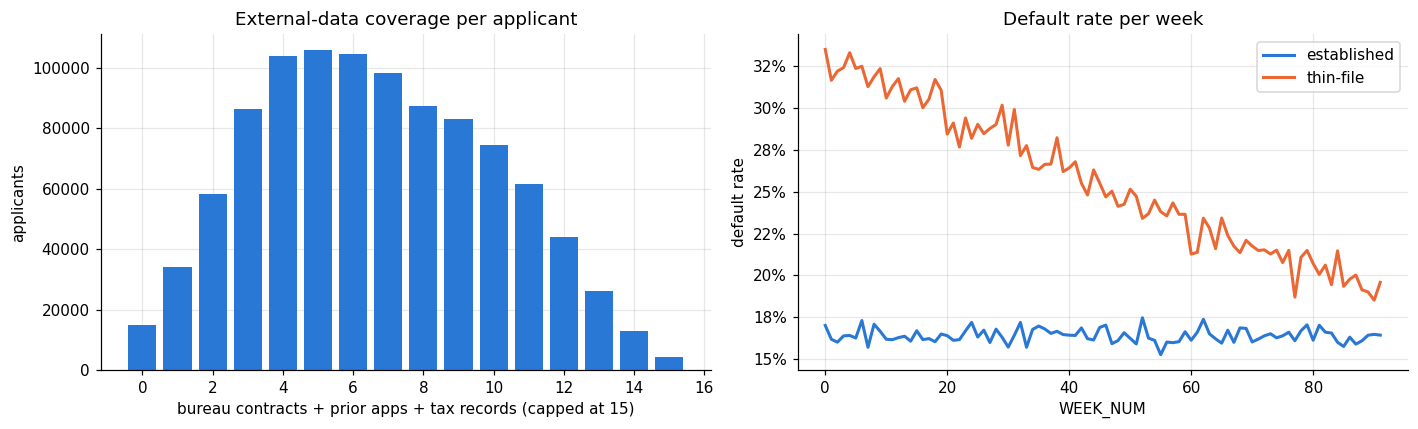

Thin-file default rate: 32.5% in weeks 0-3 -> 19.1% in weeks 88-91
Established default rate: 16.4% -> 16.4%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

coverage = train["external_coverage"].clip(upper=15).value_counts().sort_index()
axes[0].bar(coverage.index, coverage.values, color=ESTABLISHED)
axes[0].set(title="External-data coverage per applicant", xlabel="bureau contracts + prior apps + tax records (capped at 15)",
            ylabel="applicants")

weekly = train.groupby(["WEEK_NUM", "thin_file"])["target"].mean().unstack()
axes[1].plot(weekly.index, weekly[0], color=ESTABLISHED, lw=2, label="established")
axes[1].plot(weekly.index, weekly[1], color=THIN, lw=2, label="thin-file")
axes[1].set(title="Default rate per week", xlabel="WEEK_NUM", ylabel="default rate")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Thin-file default rate: {weekly[1].iloc[:4].mean():.1%} in weeks 0-3 -> {weekly[1].iloc[-4:].mean():.1%} in weeks 88-91")
print(f"Established default rate: {weekly[0].iloc[:4].mean():.1%} -> {weekly[0].iloc[-4:].mean():.1%}")

**Key finding:** thin-file risk **drifts down over time**, while established risk is flat. The test weeks (92–107) come
after all train weeks, so a model trained on train will **over-estimate thin-file risk on test**, and a flat 20% cut-off
will deny thin-file applicants who would repay. This is the inclusion gap the project closes.

### 1.4 Numeric features — distributions, skew, outliers, sentinel

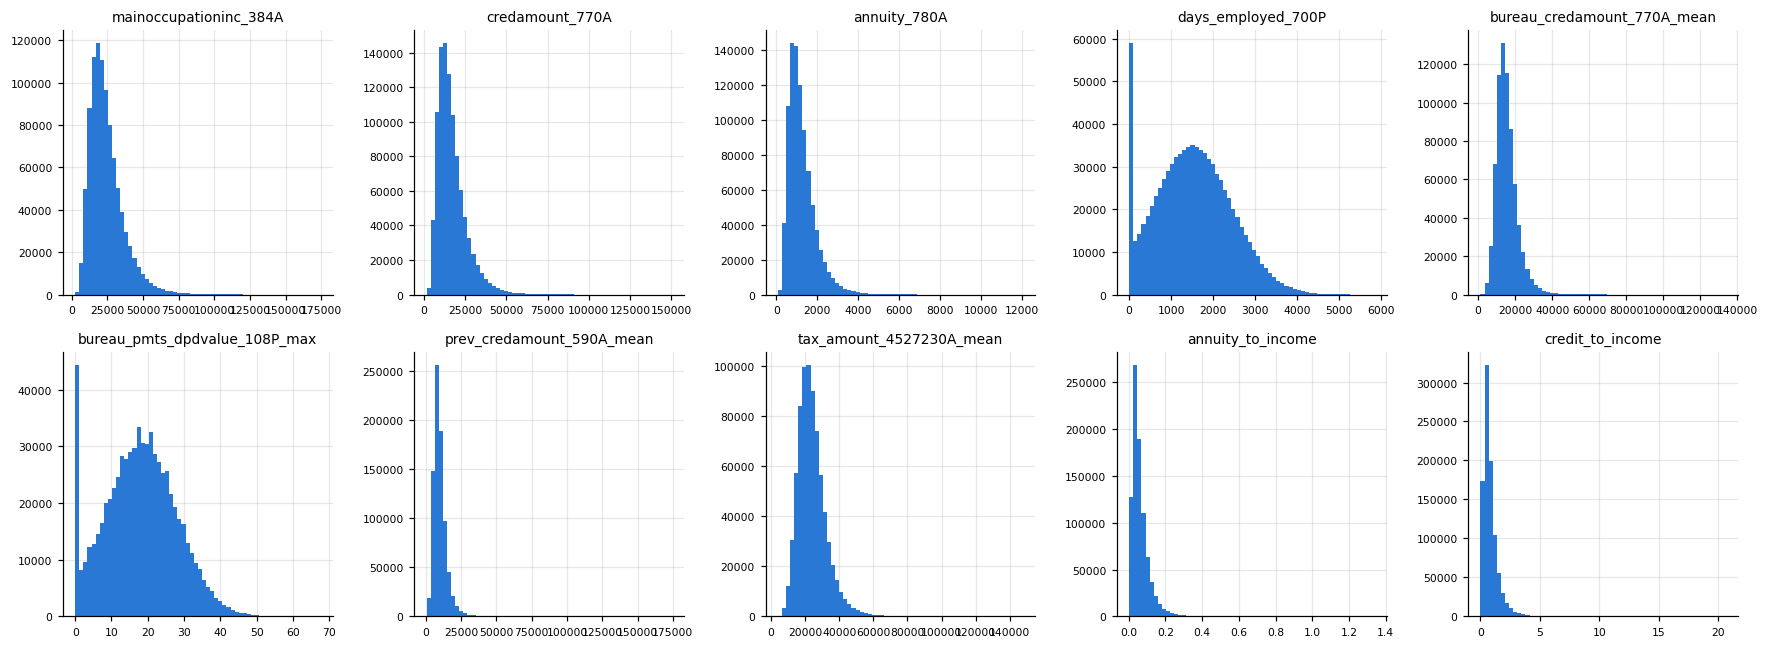

,50%,99%,99.9%,max,skew,max / p99.9
mainoccupationinc_384A,"22,021.0000","64,417.5600","91,941.2600","174,473.0000",1.5870,1.8977
credamount_770A,"14,760.0000","47,330.0000","69,800.8400","150,395.0000",1.7527,2.1546
annuity_780A,"1,097.0000","3,505.0000","5,142.6780","12,069.0000",1.7467,2.3468
days_employed_700P,"1,502.0000","3,711.0000","4,433.0000","5,852.0000",0.2601,1.3201
bureau_credamount_770A_mean,"14,557.2500","34,127.0700","51,309.8980","133,662.0000",1.6466,2.6050
bureau_pmts_dpdvalue_108P_max,17.9000,41.0000,48.8000,67.6000,0.1270,1.3852
prev_credamount_590A_mean,"8,854.5000","26,103.2500","41,402.5667","174,258.0000",2.1714,4.2089
tax_amount_4527230A_mean,"22,774.0000","50,688.4900","69,919.2980","147,877.0000",1.2894,2.1150
annuity_to_income,0.0498,0.2422,0.4097,1.3385,2.8030,3.2672
credit_to_income,0.6704,3.2605,5.4530,20.6416,2.7559,3.7854


In [9]:
NUMERIC = ["mainoccupationinc_384A", "credamount_770A", "annuity_780A", "days_employed_700P",
           "bureau_credamount_770A_mean", "bureau_pmts_dpdvalue_108P_max", "prev_credamount_590A_mean",
           "tax_amount_4527230A_mean", "annuity_to_income", "credit_to_income"]

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.flat, NUMERIC):
    ax.hist(train[col].dropna(), bins=60, color=ESTABLISHED)
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

stats = train[NUMERIC].describe(percentiles=[0.5, 0.99, 0.999]).T[["50%", "99%", "99.9%", "max"]]
stats["skew"] = train[NUMERIC].skew()
stats["max / p99.9"] = stats["max"] / stats["99.9%"]
stats

In [10]:
# The dataset docs mention a 365243 "date sentinel" (a placeholder for missing dates).
sentinel_hits = {name: int((df.drop(columns=["case_id"], errors="ignore").select_dtypes("number") == 365243).sum().sum())
                 for name, df in raw.items()}
print("Cells equal to 365243 (excluding case_id):", sentinel_hits)

Cells equal to 365243 (excluding case_id): {'base': 0, 'static_0': 0, 'static_cb_0': 0, 'person_1': 0, 'credit_bureau_a_1': 0, 'credit_bureau_a_2': 0, 'applprev_1': 0, 'tax_registry_a_1': 0}


- Amounts are right-skewed (skew ≈ 1.6–2.8) → `log1p` them for logistic regression.
- Outliers are mild (max is at most a few times the 99.9th percentile) → clip at 0.1% / 99.9% for logistic regression; trees do not care.
- No `365243` sentinel values are present in this synthetic data, so no replacement is needed.

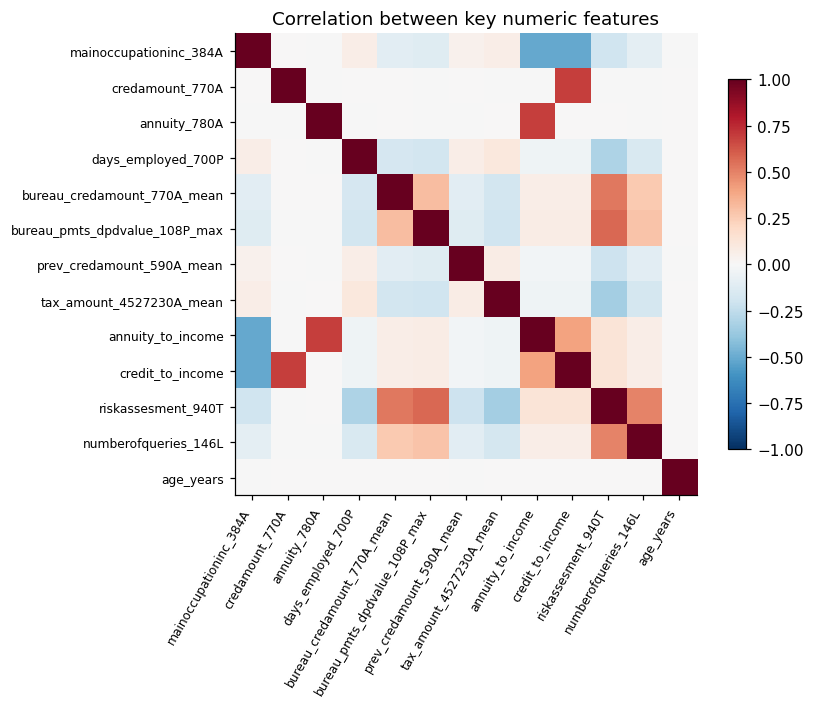

Strongest pairs:
credamount_770A                credit_to_income      0.6950
annuity_780A                   annuity_to_income     0.6950
bureau_pmts_dpdvalue_108P_max  riskassesment_940T    0.5750
bureau_credamount_770A_mean    riskassesment_940T    0.5260
mainoccupationinc_384A         annuity_to_income    -0.5120


In [11]:
corr = train[NUMERIC + ["riskassesment_940T", "numberofqueries_146L", "age_years"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
fig.colorbar(image, shrink=0.8)
ax.set_title("Correlation between key numeric features")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print("Strongest pairs:")
print(pairs.head(5).round(3).to_string())

### 1.5 Categorical features (…M) — cardinality, top values, rare values, default rate

In [12]:
rows = []
for col in features.CATEGORICAL_FEATURES:
    shares = train[col].value_counts(normalize=True)
    rows.append({
        "feature": col,
        "levels": len(shares),
        "top value": shares.index[0],
        "top share": shares.iloc[0],
        "rare share (<1%)": shares[shares < 0.01].sum(),
        "MISSING share": shares.get("MISSING", 0.0),
    })
pd.DataFrame(rows)

,feature,levels,top value,top share,rare share (<1%),MISSING share
0,education_927M,5,6def22f0,0.2797,0.0000,0.0000
1,maritalstatus_703M,4,e78cb9c0,0.2506,0.0000,0.0000
2,description_5085714M,7,MISSING,0.2998,0.0000,0.2998
3,housingtype_772M,5,39303e4a,0.2003,0.0000,0.0000


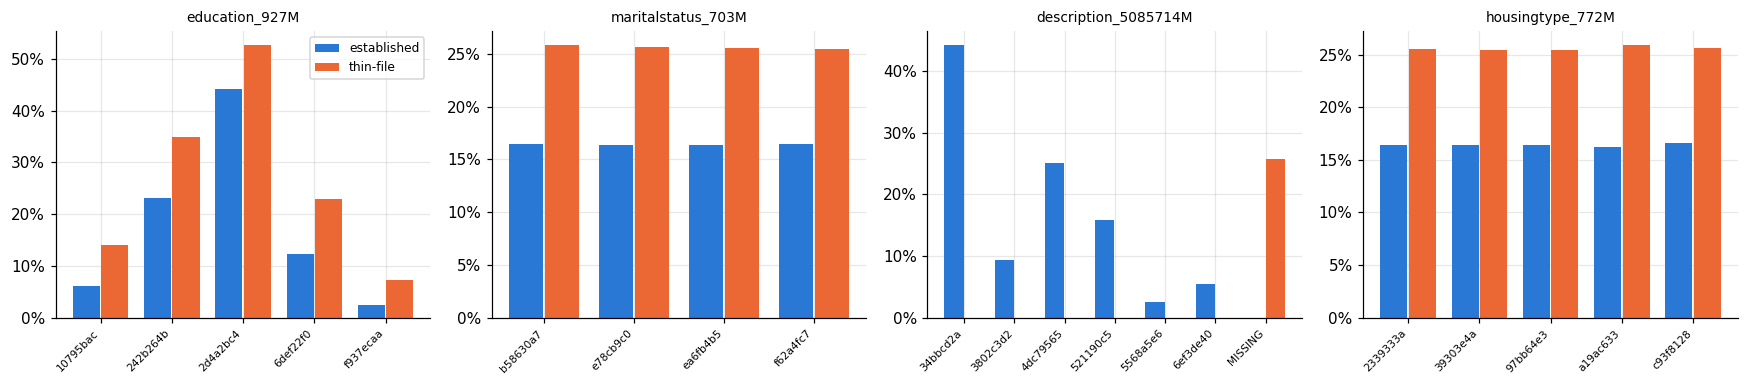

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(axes, features.CATEGORICAL_FEATURES):
    rates = train.groupby([col, "thin_file"], observed=True)["target"].mean().unstack()
    x = np.arange(len(rates))
    ax.bar(x - 0.2, rates[0], width=0.38, color=ESTABLISHED, label="established")
    if 1 in rates:
        ax.bar(x + 0.2, rates[1], width=0.38, color=THIN, label="thin-file")
    ax.set_xticks(x, rates.index, rotation=45, ha="right", fontsize=7)
    ax.set_title(col, fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

All masked categories have few levels (4–7) and no rare values, so there is nothing to collapse into "OTHER".
`education_927M` separates risk strongly in both segments; `maritalstatus_703M` and `housingtype_772M` carry almost no
signal. `description_5085714M` comes from the bureau summary, so thin-file applicants only have the `MISSING` level.

### 1.6 Signal vs default — and how it differs for thin-file applicants

Single-feature AUC: how well each feature alone separates defaulters from payers (0.5 = no signal), per segment.

In [14]:
def single_feature_auc(df, col):
    values = df[col].cat.codes if str(df[col].dtype) == "category" else df[col]
    known = values.notna()
    if known.sum() < 1000 or values[known].nunique() < 2:
        return np.nan
    auc = roc_auc_score(df.loc[known, "target"], values[known])
    return max(auc, 1 - auc)  # direction does not matter here

signal = pd.DataFrame({
    "established": {c: single_feature_auc(train[~thin], c) for c in features.feature_columns(train)},
    "thin-file": {c: single_feature_auc(train[thin], c) for c in features.feature_columns(train)},
})
signal.sort_values("established", ascending=False).head(12)

,established,thin-file
riskassesment_940T,0.7978,NaN
bureau_pmts_dpdvalue_108P_mean,0.7150,NaN
bureau_classificationofcontr_13M_share_54ddc605,0.7084,NaN
description_5085714M,0.6965,NaN
bureau_pmts_dpdvalue_108P_max,0.6758,NaN
bureau_credamount_770A_mean,0.6740,NaN
bureau_overdueamountmax_950A_mean,0.6472,NaN
bureau_classificationofcontr_13M_share_fe64f125,0.6445,NaN
numberofqueries_146L,0.6441,NaN
bureau_credamount_770A_max,0.6308,NaN


In [15]:
print("Strongest signals still available for thin-file applicants:")
signal["thin-file"].dropna().sort_values(ascending=False).head(8)

Strongest signals still available for thin-file applicants:


tax_amount_4527230A_mean              0.5873
days_employed_700P                    0.5747
tax_amount_4527230A_max               0.5737
person_empl_employedtotal_800L_mean   0.5673
prev_credamount_590A_mean             0.5551
mainoccupationinc_384A                0.5539
tax_amount_4527230A_sum               0.5499
prev_credamount_590A_max              0.5429
Name: thin-file, dtype: float64

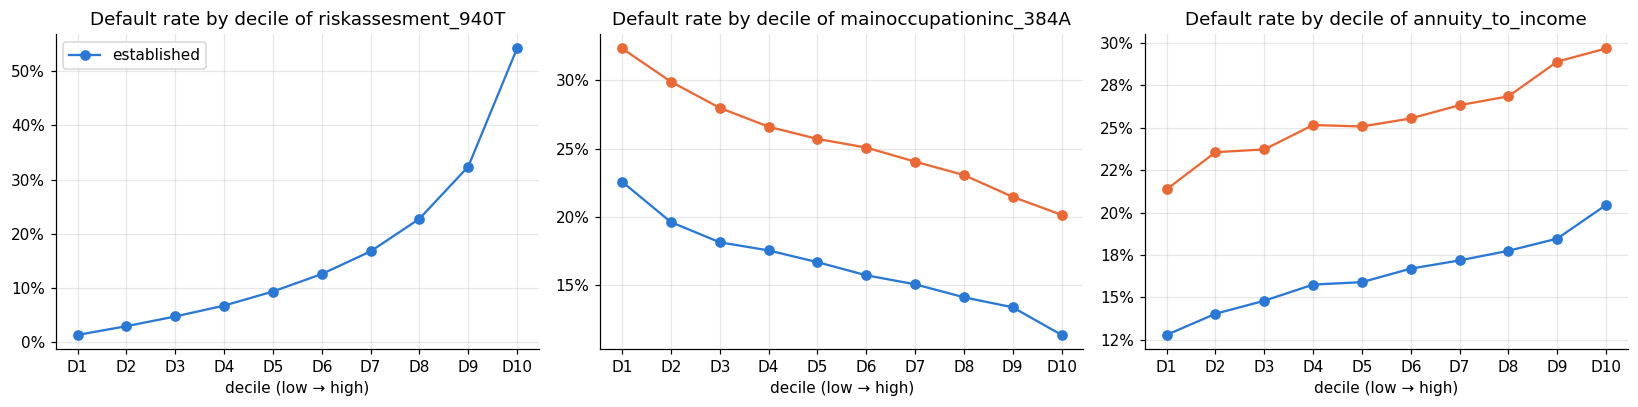

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["riskassesment_940T", "mainoccupationinc_384A", "annuity_to_income"]):
    bins = pd.qcut(train[col], 10, duplicates="drop")
    rates = train.groupby([bins, "thin_file"], observed=True)["target"].mean().unstack()
    x = np.arange(len(rates))
    ax.plot(x, rates[0], "o-", color=ESTABLISHED, label="established")
    if 1 in rates:
        ax.plot(x, rates[1], "o-", color=THIN, label="thin-file")
    ax.set_xticks(x, [f"D{i + 1}" for i in x])
    ax.set(title=f"Default rate by decile of {col}", xlabel="decile (low → high)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend()
plt.tight_layout()
plt.show()

### 1.7 Leakage and sanity checks

In [17]:
prev = raw["applprev_1"]
decision_date = prev["case_id"].map(base.set_index("case_id")["date_decision"])
feature_cols = features.feature_columns(train)

checks = {
    "train weeks": f"{train.WEEK_NUM.min()}–{train.WEEK_NUM.max()}",
    "test weeks (later = out-of-time)": f"{test.WEEK_NUM.min()}–{test.WEEK_NUM.max()}",
    "case_ids in both train and test": len(set(train.case_id) & set(test.case_id)),
    "prior approvals dated after the decision (future data)": int((prev["approvaldate_319D"] > decision_date).sum()),
    "duplicate rows in raw tables": sum(int(df.duplicated().sum()) for df in raw.values()),
    "constant feature columns": [c for c in feature_cols if train[c].nunique(dropna=False) <= 1],
    "identical feature columns (50k-row sample)": int(train[feature_cols].sample(50_000, random_state=0).T.duplicated().sum()),
    "thin-file applicants with any bureau data": int((train.loc[thin, "has_bureau_summary"] == 1).sum()),
    "time fields used as model inputs": [c for c in ["WEEK_NUM", "MONTH", "date_decision"] if c in feature_cols],
}
pd.Series(checks, name="result").to_frame()

,result
train weeks,0–91
test weeks (later = out-of-time),92–107
case_ids in both train and test,0
prior approvals dated after the decision (future data),0
duplicate rows in raw tables,0
constant feature columns,[]
identical feature columns (50k-row sample),0
thin-file applicants with any bureau data,0
time fields used as model inputs,[]


No leakage found: no shared applicants, no future-dated records, no duplicates or constant columns, and time fields are
used only to split the data, never as model inputs.

## 2. Features and time split

`features.py` builds **53 features** per loan: applicant facts, bureau aggregates (count / mean / max / sum),
payment history, prior applications, tax records, the thin-file flag and affordability ratios.
See `doc/DATA_DICTIONARY.md` for every feature.

The train file is split **by week** into three parts, so nothing is tuned on data it is later judged on:

| Weeks | Used for |
|---|---|
| 0–79 | fit the model |
| 80–85 | model validation: early stopping, Optuna tuning |
| 86–91 | policy validation: calibration, thresholds, reported validation metrics |
| 92–107 (test file) | final score, once, against `solution.csv` |

In [18]:
week = train["WEEK_NUM"]
split = pd.DataFrame({
    "loans": [(week < 80).sum(), ((week >= 80) & (week < 86)).sum(), (week >= 86).sum(), len(test)],
    "thin-file share": [thin[week < 80].mean(), thin[(week >= 80) & (week < 86)].mean(), thin[week >= 86].mean(),
                        test["thin_file"].mean()],
}, index=["fit (0–79)", "model validation (80–85)", "policy validation (86–91)", "test (92–107)"])
split

,loans,thin-file share
fit (0–79),869559,0.2999
model validation (80–85),64824,0.2991
policy validation (86–91),65617,0.2989
test (92–107),200000,0.3001


## 3. Models

Three models on the same features, each outputs a probability of default (PD). Training takes a few minutes.
Set `TUNE_TRIALS = 0` to skip the Optuna run.

In [19]:
TUNE_TRIALS = 20

experiments = [
    {"model_type": "logreg", "name": "Logistic Regression"},
    {"model_type": "random_forest", "name": "Random Forest", "sample_fraction": 0.5},
    {"model_type": "lightgbm", "name": "LightGBM"},
]
if TUNE_TRIALS:
    experiments.append({"model_type": "lightgbm", "name": f"LightGBM + Optuna ({TUNE_TRIALS} trials)",
                        "tune_trials": TUNE_TRIALS})

runs = {}
for settings in experiments:
    info = training.train(settings, log=lambda message: None)
    runs[settings["name"]] = info["run_id"]
    print(f"{settings['name']:32s} trained in {info['train_seconds']:5.1f}s")

Logistic Regression              trained in   7.8s


Random Forest                    trained in  22.8s


LightGBM                         trained in   4.7s


LightGBM + Optuna (20 trials)    trained in  69.1s


In [20]:
def metrics_table(split_name):
    rows = {}
    for name, run_id in runs.items():
        m = storage.get_run(run_id)["metrics"][split_name]
        rows[name] = {"AUC": m["all"]["auc"], "LogLoss": m["all"]["logloss"], "Brier": m["all"]["brier"],
                      "AUC established": m["established"]["auc"], "AUC thin-file": m["thin_file"]["auc"]}
    return pd.DataFrame(rows).T

validation_metrics = metrics_table("validation")
validation_metrics["AUC vs LR"] = validation_metrics["AUC"] - validation_metrics.loc["Logistic Regression", "AUC"]
print("Validation (policy weeks 86–91):")
validation_metrics

Validation (policy weeks 86–91):


,AUC,LogLoss,Brier,AUC established,AUC thin-file,AUC vs LR
Logistic Regression,0.7586,0.3966,0.1236,0.7865,0.7036,0.0000
Random Forest,0.7610,0.3944,0.1229,0.7934,0.6966,0.0024
LightGBM,0.7669,0.3912,0.1222,0.7949,0.7046,0.0083
LightGBM + Optuna (20 trials),0.7674,0.3910,0.1222,0.7957,0.7045,0.0089


Best model on validation AUC: LightGBM + Optuna (20 trials)


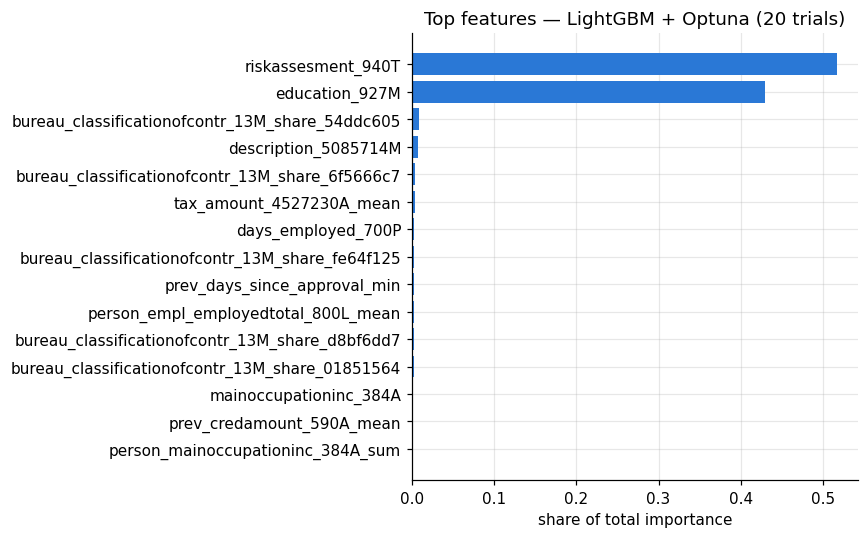

In [21]:
best_name = validation_metrics["AUC"].idxmax()
best_run = runs[best_name]
print(f"Best model on validation AUC: {best_name}")

importance = pd.DataFrame(storage.get_run(best_run)["feature_importance"]).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance["feature"][::-1], importance["importance"][::-1], color=ESTABLISHED)
ax.set(title=f"Top features — {best_name}", xlabel="share of total importance")
plt.tight_layout()
plt.show()

## 4. Decision policy

**Cost model:** repaid loan +\$2,000, default −\$8,000, denied \$0. Approving is worth
`(1 − PD) × 2,000 − PD × 8,000`, which is positive only when **PD < 20%**.

**Inclusion gap:** among applicants who actually repaid, approval rate of established minus thin-file (points).

**Inclusive Profit Score** = profit − penalty × |gap| × (applicants / 100k), only if the default rate among approved
loans stays under a ceiling (12%). Penalty: \$100k per gap point per 100k applicants.

**Second-look policy** (all fitted on the policy-validation weeks 86–91):
1. Calibrate PD separately for thin-file and established (Platt scaling).
2. Drift correction: move each PD along its segment's weekly default-rate trend, estimated on weeks 0–85.
3. One threshold per segment, chosen to maximize the Inclusive Profit Score.

In [22]:
result = analysis.get_policy_analysis(best_run)
print("Chosen thresholds:", result["options"]["thresholds"])
print("Drift trend (log-odds per week):", {k: round(v, 4) for k, v in result["calibrator"]["trend_per_week"].items()})

def policy_table(split_name):
    rows = {}
    for key, label in [("approve_all", "Approve everyone (naïve)"), ("baseline", "Baseline: raw PD < 20%"),
                       ("calibrated_flat", "Calibrated PD < 20%"), ("second_look", "Second-look policy")]:
        p = result[split_name][key]
        rows[label] = {"profit ($M)": p["profit"] / 1e6, "inclusion gap (pts)": p["inclusion_gap_pts"],
                       "approved": p["approval_rate"], "default rate of approved": p["default_rate_approved"],
                       "good thin-file approved": p["segments"]["thin_file"]["good_approval_rate"],
                       "good established approved": p["segments"]["established"]["good_approval_rate"]}
    return pd.DataFrame(rows).T

print("Validation (policy weeks 86–91) — where the thresholds were chosen:")
policy_table("validation")

Chosen thresholds: {'established': 0.175, 'thin_file': 0.245}
Drift trend (log-odds per week): {'established': -0.0, 'thin_file': -0.0084}
Validation (policy weeks 86–91) — where the thresholds were chosen:


,profit ($M),inclusion gap (pts),approved,default rate of approved,good thin-file approved,good established approved
Approve everyone (naïve),18.4340,0.0000,1.0000,0.1719,1.0000,1.0000
Baseline: raw PD < 20%,47.3800,36.2300,0.6078,0.0812,0.4176,0.7799
Calibrated PD < 20%,49.1060,9.2963,0.6938,0.0921,0.6947,0.7877
Second-look policy,49.2320,0.9399,0.6811,0.0898,0.7419,0.7513


### Final check on the out-of-time test set

Everything above was decided without the test labels. Now score the test set once against `solution.csv`.

In [23]:
test_policies = policy_table("test")
test_policies

,profit ($M),inclusion gap (pts),approved,default rate of approved,good thin-file approved,good established approved
Approve everyone (naïve),64.3800,0.0000,1.0000,0.1678,1.0000,1.0000
Baseline: raw PD < 20%,147.6740,36.8643,0.6064,0.0782,0.4123,0.7809
Calibrated PD < 20%,155.2660,9.4377,0.6950,0.0883,0.6950,0.7894
Second-look policy,153.2500,-5.3872,0.7029,0.0910,0.8057,0.7518


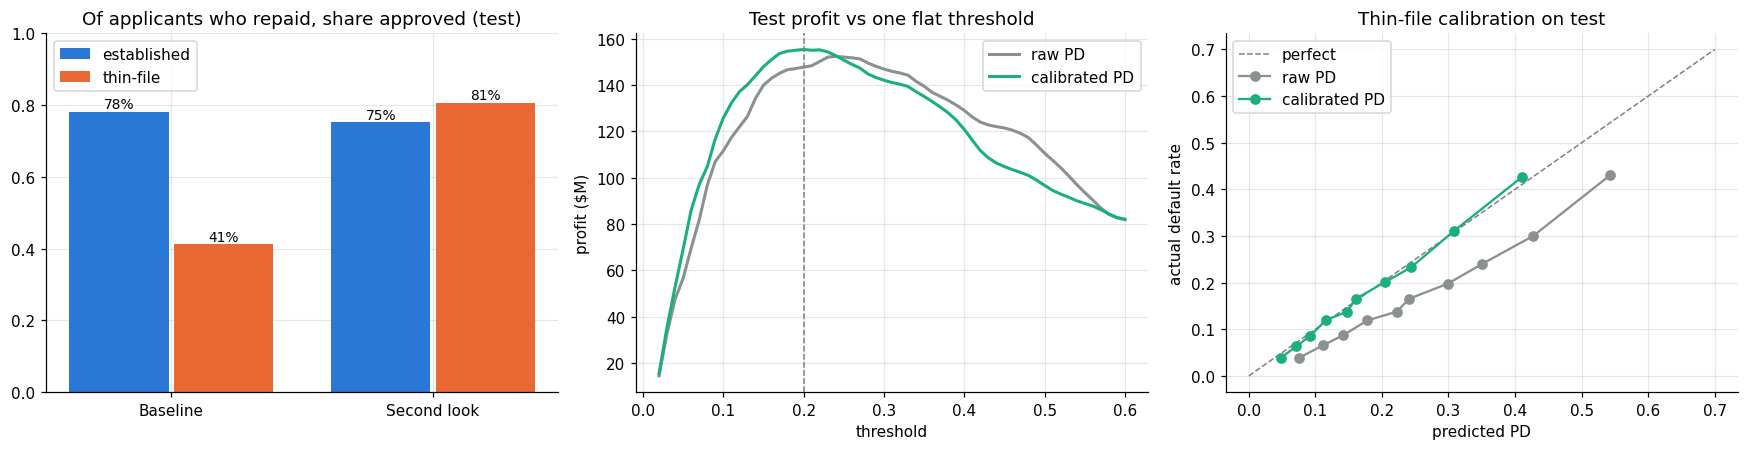

Thin-file on test: raw mean PD 25.9%, calibrated 18.0%, actual default rate 17.8%
Profit 147.7M -> 153.2M   gap 36.9 -> -5.4 pts   good thin-file payers denied 28,994 -> 9,587


In [24]:
before, after = result["test"]["baseline"], result["test"]["second_look"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

labels = ["Baseline", "Second look"]
x = np.arange(2)
est = [before["segments"]["established"]["good_approval_rate"], after["segments"]["established"]["good_approval_rate"]]
thn = [before["segments"]["thin_file"]["good_approval_rate"], after["segments"]["thin_file"]["good_approval_rate"]]
axes[0].bar(x - 0.2, est, 0.38, color=ESTABLISHED, label="established")
axes[0].bar(x + 0.2, thn, 0.38, color=THIN, label="thin-file")
for i in range(2):
    axes[0].text(i - 0.2, est[i] + 0.01, f"{est[i]:.0%}", ha="center", fontsize=9)
    axes[0].text(i + 0.2, thn[i] + 0.01, f"{thn[i]:.0%}", ha="center", fontsize=9)
axes[0].set_xticks(x, labels)
axes[0].set(title="Of applicants who repaid, share approved (test)", ylim=(0, 1))
axes[0].legend()

raw_curve = pd.DataFrame(result["profit_curve"]["raw"])
cal_curve = pd.DataFrame(result["profit_curve"]["calibrated"])
axes[1].plot(raw_curve.threshold, raw_curve.profit / 1e6, color=BASELINE, lw=2, label="raw PD")
axes[1].plot(cal_curve.threshold, cal_curve.profit / 1e6, color=SECOND_LOOK, lw=2, label="calibrated PD")
axes[1].axvline(0.2, color="gray", ls="--", lw=1)
axes[1].set(title="Test profit vs one flat threshold", xlabel="threshold", ylabel="profit ($M)")
axes[1].legend()

raw_cal = pd.DataFrame(result["calibration_table"]["raw"]["thin_file"])
new_cal = pd.DataFrame(result["calibration_table"]["calibrated"]["thin_file"])
axes[2].plot([0, 0.7], [0, 0.7], color="gray", ls="--", lw=1, label="perfect")
axes[2].plot(raw_cal.predicted, raw_cal.actual, "o-", color=BASELINE, label="raw PD")
axes[2].plot(new_cal.predicted, new_cal.actual, "o-", color=SECOND_LOOK, label="calibrated PD")
axes[2].set(title="Thin-file calibration on test", xlabel="predicted PD", ylabel="actual default rate")
axes[2].legend()
plt.tight_layout()
plt.show()

raw_m, cal_m = result["test_metrics"]["raw"]["thin_file"], result["test_metrics"]["calibrated"]["thin_file"]
print(f"Thin-file on test: raw mean PD {raw_m['mean_pd']:.1%}, calibrated {cal_m['mean_pd']:.1%}, "
      f"actual default rate {raw_m['default_rate']:.1%}")
print(f"Profit {before['profit'] / 1e6:.1f}M -> {after['profit'] / 1e6:.1f}M   "
      f"gap {before['inclusion_gap_pts']:.1f} -> {after['inclusion_gap_pts']:.1f} pts   "
      f"good thin-file payers denied {before['segments']['thin_file']['good_denied']:,} -> "
      f"{after['segments']['thin_file']['good_denied']:,}")

In [25]:
rows = {}
for name, run_id in runs.items():
    run_result = analysis.get_policy_analysis(run_id)
    b, s = run_result["test"]["baseline"], run_result["test"]["second_look"]
    m = storage.get_run(run_id)["metrics"]["test"]["all"]
    rows[name] = {"test AUC": m["auc"], "test LogLoss": m["logloss"],
                  "baseline profit ($M)": b["profit"] / 1e6, "second-look profit ($M)": s["profit"] / 1e6,
                  "baseline gap (pts)": b["inclusion_gap_pts"], "second-look gap (pts)": s["inclusion_gap_pts"]}
print("Every model, test set:")
pd.DataFrame(rows).T

Every model, test set:


,test AUC,test LogLoss,baseline profit ($M),second-look profit ($M),baseline gap (pts),second-look gap (pts)
Logistic Regression,0.7595,0.3914,144.3900,151.5320,38.4338,-1.8557
Random Forest,0.7613,0.3898,141.0460,152.7060,47.9003,-1.7872
LightGBM,0.7674,0.3863,147.5740,154.0940,35.9746,-0.3019
LightGBM + Optuna (20 trials),0.7676,0.3862,147.6740,153.2500,36.8643,-5.3872


## 5. Conclusions

- **Data:** 1M train loans, 19.2% default rate. 30% are thin-file (no bureau history). No leakage, duplicates or
  sentinel values; missing values come almost entirely from thin-file applicants lacking bureau data.
- **The trap:** thin-file default risk falls steadily over time while established risk stays flat. Trained on older weeks,
  every model over-estimates thin-file risk on the later test weeks, and a flat 20% cut-off denies many good thin-file payers.
- **Models:** LightGBM beats the logistic-regression baseline on AUC and LogLoss (success criterion 1). Thin-file AUC
  stays lower than established AUC for every model — there is simply less information about these applicants.
- **Policy:** segment-aware calibration + drift correction + segment thresholds raise profit *and* close the
  inclusion gap, for every model (success criteria 2 and 3).
- **Calibration does most of the work.** Once thin-file PDs are honest, the plain 20% rule is already far fairer and is
  the most profitable policy on test. The per-segment thresholds then trade a little profit for a smaller gap, but they
  are tuned on only 6 weeks, so they are noisier: on test they can overshoot (thin-file approved more often than
  established — a negative gap). The penalty in the Inclusive Profit Score sets how much profit we give up for fairness.
- **Method:** the model was chosen on validation AUC, and calibration and thresholds on weeks 86–91 only; the test set
  was scored once.

**Limitations and next steps:** the drift correction assumes the weekly trend continues in a straight line; a real
deployment would re-estimate it as new outcomes arrive. Confidence intervals for profit and gap (bootstrap) and
week-by-week AUC stability would strengthen the result.